# Let's Verify Step by Step (Process Reward Models)

**Paper:** [arXiv:2305.20050](https://arxiv.org/abs/2305.20050)
**Authors:** Hunter Lightman, Vineet Kosaraju, Yura Burda, Harri Edwards, Bowen Baker, Teddy Lee, Jan Leike, John Schulman, Ilya Sutskever, Karl Cobbe (2023; OpenAI)

This notebook implements a simplified **Process Reward Model (PRM)** vs **Outcome Reward Model (ORM)**
comparison from scratch in PyTorch, on synthetic multi-step arithmetic problems.
We train both reward models, then use each for best-of-N reranking and compare.

**Simplifications vs the paper** (same list, same numbers as README and CODE_ARCHITECTURE):
- Synthetic 2-step arithmetic problems instead of the MATH dataset
- GPT-2 small (124M) as both generator and reward model, instead of GPT-4
- 1,000 training solutions instead of ~1M
- 15 epochs with AdamW (lr 5e-5) instead of the paper's large-scale training
- Automated step-level labeling (ground truth) instead of 800K human labels (PRM800K)

<!-- Rules: keep real line breaks in every markdown cell; no auto-injected Kaggle validator cell; never switch matplotlib to a non-interactive backend;
silence download/progress bars; keep the notebook well under 1 MB; every claim must be visible in a saved output. -->

## 1. Setup & Imports

In [1]:
import contextlib
import io
import random
import re
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt   # keep the inline backend so plots display
from transformers import AutoTokenizer, AutoModelForCausalLM

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- Hyperparameters (the ONLY place these values live; docs copy them from here) ---
N_TRAIN_PROBLEMS = 200      # number of unique training problems
N_TEST_PROBLEMS = 50        # number of held-out test problems
N_SOLUTIONS_PER_PROBLEM = 5 # solutions sampled per problem (paper: up to 1860)
EPOCHS = 15                 # reward model training epochs
BATCH_SIZE = 8
LR = 5e-5
MAX_NEW_TOKENS = 80         # generation length for solutions
BEST_OF_N_VALUES = [1, 2, 3, 5]  # N values for best-of-N evaluation

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cuda


## 2. Data

We generate synthetic multi-step arithmetic problems. Each problem is a sequence
of arithmetic operations (e.g. "12 + 34 - 5 = ?") with a known final answer.
We also track the intermediate result after each step, which gives us ground-truth
step-level labels for process supervision — a luxury the paper did not have (they
used 800K human labels in PRM800K).

In [2]:
def generate_arithmetic_problem(rng):
    """Generate a 2-step arithmetic problem with intermediate results.
    Returns (problem_str, steps, final_answer).
    steps is a list of (step_text, intermediate_result, is_correct).
    """
    a = rng.randint(1, 50)
    b = rng.randint(1, 50)
    c = rng.randint(1, 30)
    ops = rng.sample(['+', '-', '*'], 2)
    
    # Compute step by step
    if ops[0] == '+':
        r1 = a + b
    elif ops[0] == '-':
        r1 = a - b
    else:
        r1 = a * b
    
    if ops[1] == '+':
        r2 = r1 + c
    elif ops[1] == '-':
        r2 = r1 - c
    else:
        r2 = r1 * c
    
    problem_str = f'{a} {ops[0]} {b} {ops[1]} {c}'
    steps = [
        f'{a} {ops[0]} {b} = {r1}',
        f'{r1} {ops[1]} {c} = {r2}',
    ]
    return problem_str, steps, r2

def format_solution(problem_str, steps, final_answer):
    """Format a correct solution as text."""
    lines = [f'Problem: {problem_str}']
    for s in steps:
        lines.append(s)
    lines.append(f'Answer: {final_answer}')
    return '\n'.join(lines)

# Generate training and test problems
rng = random.Random(SEED)
train_problems = [generate_arithmetic_problem(rng) for _ in range(N_TRAIN_PROBLEMS)]
test_problems = [generate_arithmetic_problem(rng) for _ in range(N_TEST_PROBLEMS)]

# Show examples
print(f'Training problems: {len(train_problems)}')
print(f'Test problems: {len(test_problems)}')
print()
for i in range(3):
    p, steps, ans = train_problems[i]
    print(f'Example {i+1}: {p}')
    for s in steps:
        print(f'  {s}')
    print(f'  Answer: {ans}')
    print()

Training problems: 200
Test problems: 50

Example 1: 41 * 8 - 1
  41 * 8 = 328
  328 - 1 = 327
  Answer: 327

Example 2: 16 * 15 + 5
  16 * 15 = 240
  240 + 5 = 245
  Answer: 245

Example 3: 44 * 48 + 29
  44 * 48 = 2112
  2112 + 29 = 2141
  Answer: 2141



## 3. Model & Tokenizer

We use **GPT-2 small** (124M parameters) from HuggingFace as the base model for
both the generator and the reward models. The paper used GPT-4 as the base model.
The reward models are trained by adding a classification head on top of GPT-2
that predicts whether each step is correct (PRM) or whether the overall solution
is correct (ORM).

In [3]:
with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(io.StringIO()):
    tokenizer = AutoTokenizer.from_pretrained('gpt2')
    tokenizer.pad_token = tokenizer.eos_token
    base_model = AutoModelForCausalLM.from_pretrained('gpt2')

n_params = sum(p.numel() for p in base_model.parameters())
print(f'GPT-2 small parameters: {n_params:,}')
print(f'Vocab size: {tokenizer.vocab_size}')
print(f'Max context: {base_model.config.n_ctx}')

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT-2 small parameters: 124,439,808
Vocab size: 50257
Max context: 1024


## 4. Solution Generation

We need a pool of solutions for each problem — some correct, some incorrect —
to train and evaluate the reward models. Rather than fine-tuning GPT-2 as a
generator (which the paper did), we generate solutions programmatically:
correct solutions follow the ground-truth steps, while incorrect solutions
introduce errors at random steps. This gives us precise control over where
errors occur, which is essential for training a PRM that detects step-level errors.

In [4]:
def generate_correct_solution(problem_str, steps, final_answer):
    """Generate a correct solution string."""
    lines = [f'Problem: {problem_str}']
    for s in steps:
        lines.append(s)
    lines.append(f'Answer: {final_answer}')
    return '\n'.join(lines)

def generate_incorrect_solution(problem_str, steps, final_answer, rng, error_step=None):
    """Generate an incorrect solution with an error at a specific or random step.
    Returns (solution_text, step_labels) where step_labels is a list of
    1 (correct) or 0 (incorrect) for each step.
    """
    if error_step is None:
        error_step = rng.randint(0, len(steps) - 1)
    
    step_labels = []
    lines = [f'Problem: {problem_str}']
    prev_result = None
    
    for i, s in enumerate(steps):
        if i < error_step:
            # Correct step
            lines.append(s)
            step_labels.append(1)
            # Parse the result from this step
            prev_result = int(s.split('= ')[1])
        elif i == error_step:
            # Introduce an error: wrong result
            correct_val = int(s.split('= ')[1])
            wrong_val = correct_val + rng.choice([-5, -3, -1, 1, 3, 5, 7])
            step_parts = s.split(' = ')
            lines.append(f'{step_parts[0]} = {wrong_val}')
            step_labels.append(0)
            prev_result = wrong_val
        else:
            # Propagate the error: use the wrong previous result
            # Parse the operation from the original step
            step_parts = s.split(' = ')
            op_part = step_parts[0]
            # Replace the first number with prev_result
            parts = op_part.split()
            # Format: "r1 op c" -> replace r1 with prev_result
            parts[0] = str(prev_result)
            op = parts[1]
            operand = int(parts[2])
            if op == '+':
                new_result = prev_result + operand
            elif op == '-':
                new_result = prev_result - operand
            else:
                new_result = prev_result * operand
            lines.append(f'{" ".join(parts)} = {new_result}')
            step_labels.append(0)  # downstream step is also wrong
            prev_result = new_result
    
    # Wrong final answer
    lines.append(f'Answer: {prev_result}')
    return '\n'.join(lines), step_labels

def generate_solution_pool(problem_str, steps, final_answer, n_solutions, rng):
    """Generate a pool of solutions for one problem.
    Returns list of (solution_text, step_labels, is_correct).
    """
    solutions = []
    # Always include a correct solution
    correct_text = generate_correct_solution(problem_str, steps, final_answer)
    step_labels = [1] * len(steps)
    solutions.append((correct_text, step_labels, True))
    
    # Generate incorrect solutions with errors at different steps
    for _ in range(n_solutions - 1):
        sol_text, labels = generate_incorrect_solution(
            problem_str, steps, final_answer, rng
        )
        solutions.append((sol_text, labels, False))
    
    rng.shuffle(solutions)
    return solutions

# Generate solution pool for training problems
gen_rng = random.Random(SEED + 1)
train_solutions = []
for p, steps, ans in train_problems:
    pool = generate_solution_pool(p, steps, ans, N_SOLUTIONS_PER_PROBLEM, gen_rng)
    for sol_text, step_labels, is_correct in pool:
        train_solutions.append({
            'text': sol_text,
            'step_labels': step_labels,
            'is_correct': is_correct,
        })

print(f'Total training solutions: {len(train_solutions)}')
n_correct = sum(1 for s in train_solutions if s['is_correct'])
n_incorrect = len(train_solutions) - n_correct
print(f'  Correct: {n_correct} ({100*n_correct/len(train_solutions):.1f}%)')
print(f'  Incorrect: {n_incorrect} ({100*n_incorrect/len(train_solutions):.1f}%)')
print()
# Show an example incorrect solution
for s in train_solutions:
    if not s['is_correct']:
        print('Example incorrect solution:')
        print(s['text'])
        print(f'Step labels: {s["step_labels"]}')
        break

Total training solutions: 1000
  Correct: 200 (20.0%)
  Incorrect: 800 (80.0%)

Example incorrect solution:
Problem: 41 * 8 - 1
41 * 8 = 327
327 - 1 = 326
Answer: 326
Step labels: [0, 0]


## 5. Process Reward Model (PRM)

The PRM predicts whether each step in a solution is correct. Following the paper
(Section 2.6), we train the PRM to predict step correctness at the last token of
each step. We use GPT-2 with a single-token classification head.

At test time, the PRM score for a solution is the product of per-step probabilities
that each step is correct (Section F.2 of the paper: the best-performing reduction).

In [5]:
class RewardModel(nn.Module):
    """GPT-2 with a binary classification head for step-level or solution-level scoring."""
    def __init__(self, base_model):
        super().__init__()
        self.transformer = base_model.transformer  # GPT-2 transformer body
        self.score_head = nn.Linear(base_model.config.n_embd, 1)
    
    def forward(self, input_ids, attention_mask=None):
        """Returns per-token scores (batch, seq_len, 1)."""
        outputs = self.transformer(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )
        hidden = outputs[0]  # (batch, seq, n_embd)
        scores = self.score_head(hidden)    # (batch, seq, 1)
        return scores.squeeze(-1)           # (batch, seq)

# Create PRM and ORM (separate copies)
with contextlib.redirect_stderr(io.StringIO()):
    base_prm = AutoModelForCausalLM.from_pretrained('gpt2')
    base_orm = AutoModelForCausalLM.from_pretrained('gpt2')

prm = RewardModel(base_prm).to(DEVICE)
orm = RewardModel(base_orm).to(DEVICE)

prm_params = sum(p.numel() for p in prm.parameters())
orm_params = sum(p.numel() for p in orm.parameters())
print(f'PRM parameters: {prm_params:,}')
print(f'ORM parameters: {orm_params:,}')

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

PRM parameters: 124,440,577
ORM parameters: 124,440,577


## 6. Tokenization & Label Preparation

For the PRM, we need to identify the token positions corresponding to the end of
each step, so we can compute the loss only at those positions. For the ORM, we
use the final token of the solution.

In [6]:
def find_step_end_positions(text, step_labels, tokenizer):
    """Tokenize text and find the token position at the end of each step.
    Returns (input_ids, step_end_positions, step_labels).
    """
    lines = text.split('\n')
    input_ids = []
    step_end_positions = []
    
    current_text = ''
    for i, line in enumerate(lines):
        if line.startswith('Problem:'):
            current_text = line + '\n'
            ids = tokenizer.encode(current_text, add_special_tokens=False)
            input_ids.extend(ids)
        elif line.startswith('Answer:'):
            # Final answer line - add it
            current_text = line
            ids = tokenizer.encode(current_text, add_special_tokens=False)
            input_ids.extend(ids)
        else:
            # This is a step line
            current_text = line + '\n'
            ids = tokenizer.encode(current_text, add_special_tokens=False)
            input_ids.extend(ids)
            # The position of the last token of this step
            step_end_positions.append(len(input_ids) - 1)
    
    return input_ids, step_end_positions, step_labels

def prepare_prm_batch(solutions, tokenizer, max_len=256):
    """Prepare a batch for PRM training.
    Returns (input_ids, attention_mask, token_labels, step_positions).
    token_labels: -1 (ignore) everywhere except at step end positions,
                  where it is 1 (correct) or 0 (incorrect).
    """
    batch_input_ids = []
    batch_attention_mask = []
    batch_token_labels = []
    
    for sol in solutions:
        ids, step_ends, step_labels = find_step_end_positions(
            sol['text'], sol['step_labels'], tokenizer
        )
        ids = ids[:max_len]
        step_ends = [p for p in step_ends if p < max_len]
        step_labels = step_labels[:len(step_ends)]
        
        token_labels = [-1] * len(ids)
        for pos, label in zip(step_ends, step_labels):
            token_labels[pos] = label
        
        # Pad to max_len
        pad_len = max_len - len(ids)
        attention_mask = [1] * len(ids) + [0] * pad_len
        ids = ids + [tokenizer.pad_token_id] * pad_len
        token_labels = token_labels + [-1] * pad_len
        
        batch_input_ids.append(ids)
        batch_attention_mask.append(attention_mask)
        batch_token_labels.append(token_labels)
    
    return (
        torch.tensor(batch_input_ids, dtype=torch.long),
        torch.tensor(batch_attention_mask, dtype=torch.long),
        torch.tensor(batch_token_labels, dtype=torch.float),
    )

def prepare_orm_batch(solutions, tokenizer, max_len=256):
    """Prepare a batch for ORM training.
    token_labels: -1 everywhere except the last non-pad token,
                  where it is 1 (correct) or 0 (incorrect).
    """
    batch_input_ids = []
    batch_attention_mask = []
    batch_token_labels = []
    
    for sol in solutions:
        ids = tokenizer.encode(sol['text'], add_special_tokens=False)[:max_len]
        token_labels = [-1] * len(ids)
        token_labels[-1] = 1 if sol['is_correct'] else 0
        
        pad_len = max_len - len(ids)
        attention_mask = [1] * len(ids) + [0] * pad_len
        ids = ids + [tokenizer.pad_token_id] * pad_len
        token_labels = token_labels + [-1] * pad_len
        
        batch_input_ids.append(ids)
        batch_attention_mask.append(attention_mask)
        batch_token_labels.append(token_labels)
    
    return (
        torch.tensor(batch_input_ids, dtype=torch.long),
        torch.tensor(batch_attention_mask, dtype=torch.long),
        torch.tensor(batch_token_labels, dtype=torch.float),
    )

# Test tokenization on one example
test_ids, test_step_ends, test_labels = find_step_end_positions(
    train_solutions[0]['text'], train_solutions[0]['step_labels'], tokenizer
)
print(f'Example tokenization:')
print(f'  Total tokens: {len(test_ids)}')
print(f'  Step end positions: {test_step_ends}')
print(f'  Step labels: {test_labels}')
print(f'  Decoded: {tokenizer.decode(test_ids[:30])}...')

Example tokenization:
  Total tokens: 23
  Step end positions: [13, 19]
  Step labels: [0, 0]
  Decoded: Problem: 41 * 8 - 1
41 * 8 = 327
327 - 1 = 326
Answer: 326...


## 7. Training the PRM (Process Reward Model)

The PRM is trained with binary cross-entropy loss at step-end token positions.
Following the paper (Section 2.6), the model predicts step correctness at the
last token of each step.

In [7]:
def train_reward_model(model, solutions, tokenizer, epochs, batch_size, lr, label_type='prm'):
    """Train a reward model (PRM or ORM).
    label_type: 'prm' for step-level labels, 'orm' for outcome labels.
    """
    optimizer = optim.AdamW(model.parameters(), lr=lr)
    model.train()
    history = {'loss': [], 'accuracy': []}
    start = time.time()
    
    for epoch in range(1, epochs + 1):
        epoch_loss = 0.0
        n_batches = 0
        all_preds = []
        all_labels = []
        
        # Shuffle
        indices = list(range(len(solutions)))
        random.shuffle(indices)
        
        for i in range(0, len(indices), batch_size):
            batch_indices = indices[i:i+batch_size]
            batch_solutions = [solutions[j] for j in batch_indices]
            
            if label_type == 'prm':
                input_ids, attn_mask, token_labels = prepare_prm_batch(
                    batch_solutions, tokenizer
                )
            else:
                input_ids, attn_mask, token_labels = prepare_orm_batch(
                    batch_solutions, tokenizer
                )
            
            input_ids = input_ids.to(DEVICE)
            attn_mask = attn_mask.to(DEVICE)
            token_labels = token_labels.to(DEVICE)
            
            scores = model(input_ids, attn_mask)  # (batch, seq)
            
            # BCE loss only at labeled positions (token_labels != -1)
            mask = token_labels >= 0
            if mask.sum() == 0:
                continue
            
            loss = F.binary_cross_entropy_with_logits(
                scores[mask], token_labels[mask]
            )
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            n_batches += 1
            
            # Track accuracy
            with torch.no_grad():
                preds = (torch.sigmoid(scores[mask]) > 0.5).float()
                all_preds.extend(preds.cpu().tolist())
                all_labels.extend(token_labels[mask].cpu().tolist())
        
        avg_loss = epoch_loss / max(n_batches, 1)
        accuracy = sum(1 for p, l in zip(all_preds, all_labels) if p == l) / max(len(all_labels), 1)
        history['loss'].append(avg_loss)
        history['accuracy'].append(accuracy)
        
        if epoch == 1 or epoch % 5 == 0:
            print(f'  Epoch [{epoch:3d}/{epochs}]  loss {avg_loss:.4f}  acc {accuracy:.4f}  [{time.time()-start:.0f}s]')
    
    print(f'  Training time: {time.time()-start:.0f}s')
    return history

print('=== Training PRM (Process Reward Model) ===')
prm_history = train_reward_model(
    prm, train_solutions, tokenizer, EPOCHS, BATCH_SIZE, LR, label_type='prm'
)

=== Training PRM (Process Reward Model) ===


  Epoch [  1/15]  loss 0.6737  acc 0.6230  [52s]


  Epoch [  5/15]  loss 0.5124  acc 0.7630  [278s]


  Epoch [ 10/15]  loss 0.6719  acc 0.5910  [563s]


  Epoch [ 15/15]  loss 0.4785  acc 0.7825  [848s]
  Training time: 848s


## 8. Training the ORM (Outcome Reward Model)

The ORM is trained with binary cross-entropy loss at the final token of each
solution, predicting whether the overall solution is correct (Section 2.5).
This matches the paper's outcome supervision: the model only sees whether the
final answer is right, not which step went wrong.

In [8]:
print('=== Training ORM (Outcome Reward Model) ===')
orm_history = train_reward_model(
    orm, train_solutions, tokenizer, EPOCHS, BATCH_SIZE, LR, label_type='orm'
)

=== Training ORM (Outcome Reward Model) ===


  Epoch [  1/15]  loss 0.5596  acc 0.7810  [57s]


  Epoch [  5/15]  loss 0.5051  acc 0.8000  [285s]


  Epoch [ 10/15]  loss 0.3690  acc 0.8310  [569s]


  Epoch [ 15/15]  loss 0.1418  acc 0.9490  [854s]
  Training time: 854s


## 9. Training Curves

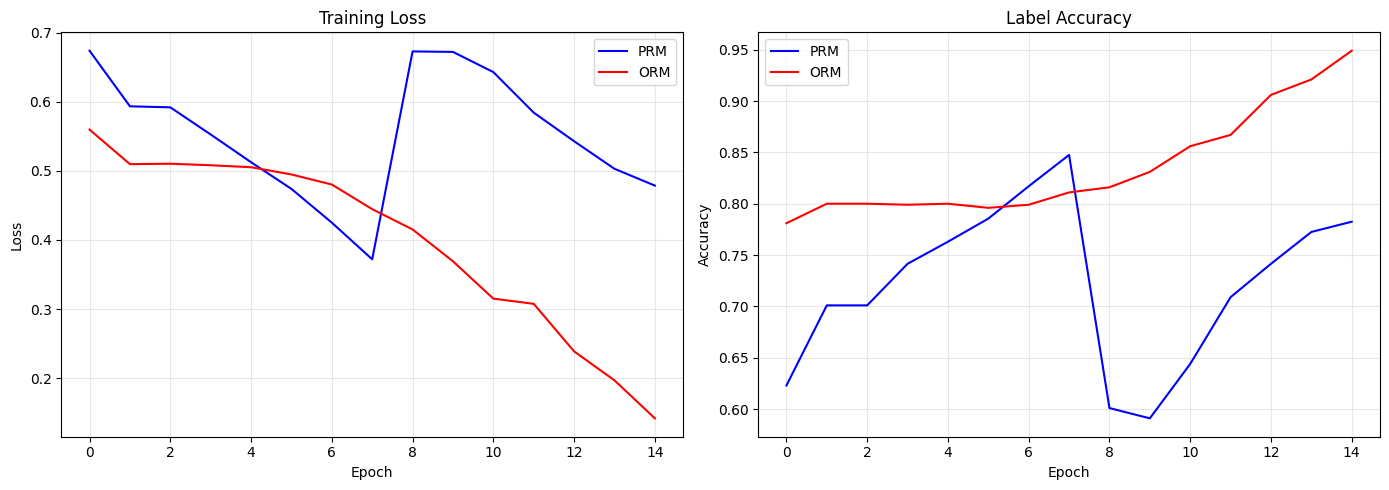

PRM final loss: 0.4785, final accuracy: 0.7825
ORM final loss: 0.1418, final accuracy: 0.9490


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(prm_history['loss'], label='PRM', color='blue')
axes[0].plot(orm_history['loss'], label='ORM', color='red')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(prm_history['accuracy'], label='PRM', color='blue')
axes[1].plot(orm_history['accuracy'], label='ORM', color='red')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Label Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f'PRM final loss: {prm_history["loss"][-1]:.4f}, final accuracy: {prm_history["accuracy"][-1]:.4f}')
print(f'ORM final loss: {orm_history["loss"][-1]:.4f}, final accuracy: {orm_history["accuracy"][-1]:.4f}')

## 10. Scoring Solutions

Following the paper (Section F.2), the PRM score for a solution is the **product**
of per-step probabilities that each step is correct. The ORM score is the
probability that the overall solution is correct (prediction at the final token).

In [10]:
@torch.no_grad()
def prm_score_solution(model, solution_text, tokenizer, max_len=256):
    """Score a solution with the PRM.
    Returns the product of per-step correctness probabilities.
    """
    ids = tokenizer.encode(solution_text, add_special_tokens=False)[:max_len]
    input_ids = torch.tensor([ids], dtype=torch.long).to(DEVICE)
    attn_mask = torch.ones_like(input_ids).to(DEVICE)
    
    scores = model(input_ids, attn_mask)  # (1, seq)
    probs = torch.sigmoid(scores[0])  # (seq,)
    
    # Find step end positions (same logic as find_step_end_positions)
    lines = solution_text.split('\n')
    cumulative_len = 0
    step_end_positions = []
    for line in lines:
        line_text = line + '\n'
        line_ids = tokenizer.encode(line_text, add_special_tokens=False)
        cumulative_len += len(line_ids)
        if not line.startswith('Problem:') and not line.startswith('Answer:'):
            step_end_positions.append(min(cumulative_len - 1, max_len - 1))
    
    if not step_end_positions:
        return 0.5
    
    step_probs = [probs[p].item() for p in step_end_positions]
    # Product of step probabilities (paper's best strategy, Section F.2)
    score = 1.0
    for p in step_probs:
        score *= p
    return score

@torch.no_grad()
def orm_score_solution(model, solution_text, tokenizer, max_len=256):
    """Score a solution with the ORM.
    Returns the probability at the final token.
    """
    ids = tokenizer.encode(solution_text, add_special_tokens=False)[:max_len]
    input_ids = torch.tensor([ids], dtype=torch.long).to(DEVICE)
    attn_mask = torch.ones_like(input_ids).to(DEVICE)
    
    scores = model(input_ids, attn_mask)  # (1, seq)
    prob = torch.sigmoid(scores[0, -1]).item()
    return prob

# Test scoring on a few examples
print('=== Scoring examples ===')
for i in range(4):
    sol = train_solutions[i]
    prm_s = prm_score_solution(prm, sol['text'], tokenizer)
    orm_s = orm_score_solution(orm, sol['text'], tokenizer)
    print(f'Solution {i+1}: correct={sol["is_correct"]}  PRM={prm_s:.4f}  ORM={orm_s:.4f}')
    print(f'  Step labels: {sol["step_labels"]}')

=== Scoring examples ===
Solution 1: correct=False  PRM=0.0718  ORM=0.0033
  Step labels: [0, 0]
Solution 2: correct=True  PRM=0.2083  ORM=0.9999
  Step labels: [1, 1]
Solution 3: correct=False  PRM=0.0000  ORM=0.0001
  Step labels: [0, 0]
Solution 4: correct=False  PRM=0.0691  ORM=0.0010
  Step labels: [1, 0]


## 11. Best-of-N Reranking

Following the paper (Section 2.1), we evaluate each reward model by its ability
to perform best-of-N search. For each test problem, we generate N candidate
solutions, select the one ranked highest by the reward model, and check if it
is correct. We compare PRM, ORM, and majority voting (a strong baseline noted
in the paper, Figure 3).

In [11]:
def best_of_n_eval(test_problems, n_solutions, prm, orm, tokenizer, n_values):
    """Evaluate best-of-N reranking for PRM, ORM, and majority voting.
    Returns dict of results.
    """
    eval_rng = random.Random(SEED + 100)
    results = {
        'N': n_values,
        'prm': [], 'orm': [], 'majority': [], 'random': []
    }
    
    # Generate solution pools for all test problems
    all_pools = []
    for p, steps, ans in test_problems:
        # Generate max_n solutions (mix of correct and incorrect)
        max_n = max(n_values)
        pool = generate_solution_pool(p, steps, ans, max_n, eval_rng)
        all_pools.append(pool)
    
    for n in n_values:
        prm_correct = 0
        orm_correct = 0
        maj_correct = 0
        rand_correct = 0
        total = len(test_problems)
        
        for pool in all_pools:
            candidates = pool[:n]
            
            # PRM: select highest PRM score
            prm_scores = [prm_score_solution(prm, sol[0], tokenizer) for sol in candidates]
            prm_best = candidates[np.argmax(prm_scores)]
            if prm_best[2]:  # is_correct
                prm_correct += 1
            
            # ORM: select highest ORM score
            orm_scores = [orm_score_solution(orm, sol[0], tokenizer) for sol in candidates]
            orm_best = candidates[np.argmax(orm_scores)]
            if orm_best[2]:
                orm_correct += 1
            
            # Majority voting: pick the most common final answer
            answers = []
            for sol in candidates:
                # Extract answer from last line
                last_line = sol[0].split('\n')[-1]
                try:
                    ans_val = int(last_line.replace('Answer: ', ''))
                except ValueError:
                    ans_val = last_line
                answers.append(ans_val)
            from collections import Counter
            most_common_ans = Counter(answers).most_common(1)[0][0]
            # Check if the most common answer is correct
            if any(sol[2] for sol in candidates):
                correct_ans = None
                for sol in candidates:
                    if sol[2]:
                        last_line = sol[0].split('\n')[-1]
                        correct_ans = int(last_line.replace('Answer: ', ''))
                        break
                if most_common_ans == correct_ans:
                    maj_correct += 1
            
            # Random: pick a random solution
            rand_idx = eval_rng.randint(0, n - 1)
            if candidates[rand_idx][2]:
                rand_correct += 1
        
        results['prm'].append(100 * prm_correct / total)
        results['orm'].append(100 * orm_correct / total)
        results['majority'].append(100 * maj_correct / total)
        results['random'].append(100 * rand_correct / total)
        
        print(f'  N={n:3d}: PRM {100*prm_correct/total:5.1f}%  ORM {100*orm_correct/total:5.1f}%  '
              f'Majority {100*maj_correct/total:5.1f}%  Random {100*rand_correct/total:5.1f}%')
    
    return results

print('=== Best-of-N Reranking Evaluation ===')
print(f'Test problems: {N_TEST_PROBLEMS}')
bon_results = best_of_n_eval(
    test_problems, N_SOLUTIONS_PER_PROBLEM, prm, orm, tokenizer, BEST_OF_N_VALUES
)

=== Best-of-N Reranking Evaluation ===
Test problems: 50


  N=  1: PRM  22.0%  ORM  22.0%  Majority  22.0%  Random  22.0%


  N=  2: PRM  16.0%  ORM  20.0%  Majority  22.0%  Random  16.0%


  N=  3: PRM  28.0%  ORM  16.0%  Majority  20.0%  Random  24.0%


  N=  5: PRM  36.0%  ORM  20.0%  Majority  14.0%  Random  30.0%


## 12. Best-of-N Results Visualization

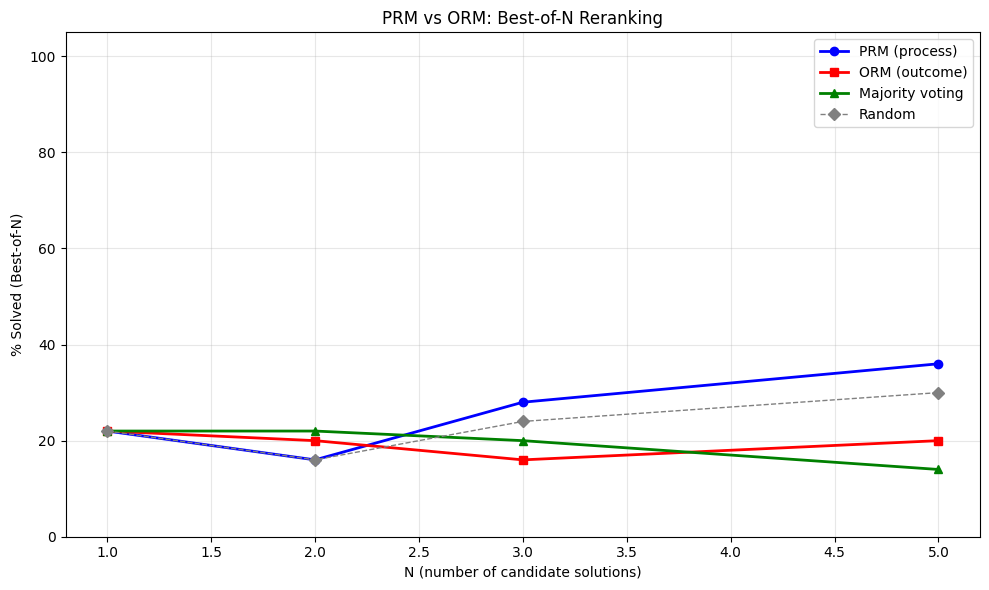

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(bon_results['N'], bon_results['prm'], 'o-', label='PRM (process)', color='blue', linewidth=2)
ax.plot(bon_results['N'], bon_results['orm'], 's-', label='ORM (outcome)', color='red', linewidth=2)
ax.plot(bon_results['N'], bon_results['majority'], '^-', label='Majority voting', color='green', linewidth=2)
ax.plot(bon_results['N'], bon_results['random'], 'D--', label='Random', color='gray', linewidth=1)

ax.set_xlabel('N (number of candidate solutions)')
ax.set_ylabel('% Solved (Best-of-N)')
ax.set_title('PRM vs ORM: Best-of-N Reranking')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim(0, 105)

plt.tight_layout()
plt.show()

## 13. PRM Step-Level Visualization

The paper's Figure 2 visualizes the PRM's per-step scores for correct and
incorrect solutions. We reproduce a similar visualization: for one correct and
one incorrect solution, we show the PRM's per-step correctness probability.

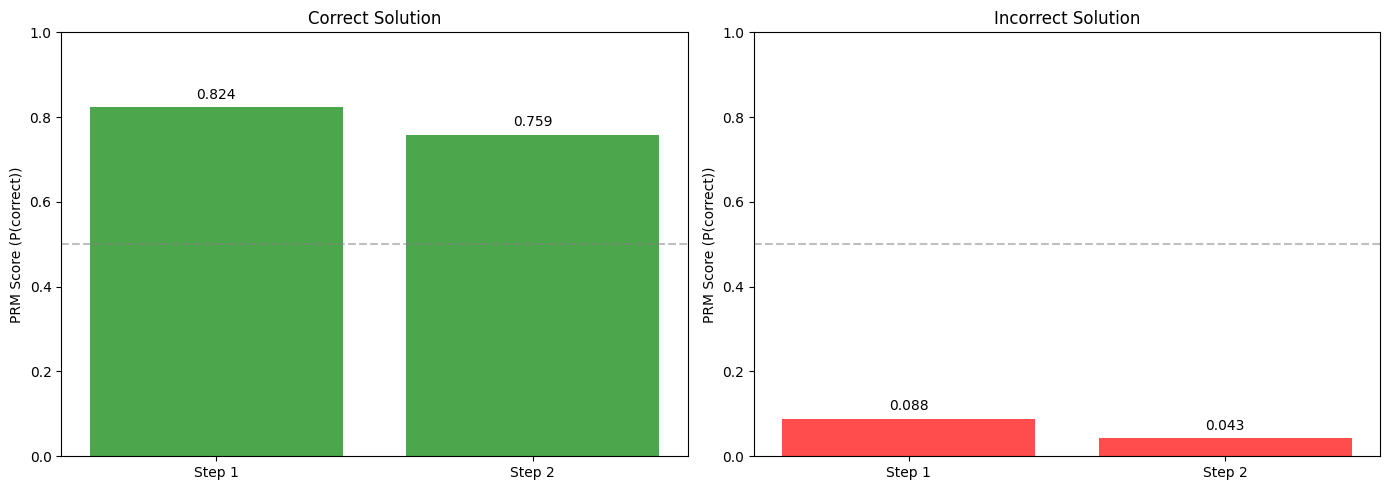

Correct solution:
Problem: 28 + 8 * 18
28 + 8 = 36
36 * 18 = 648
Answer: 648

Incorrect solution:
Problem: 28 + 8 * 18
28 + 8 = 31
31 * 18 = 558
Answer: 558


In [13]:
# Pick one correct and one incorrect test solution
viz_pool = all_pools[0] if 'all_pools' in dir() else generate_solution_pool(
    test_problems[0][0], test_problems[0][1], test_problems[0][2],
    max(BEST_OF_N_VALUES), random.Random(SEED + 200)
)
correct_sol = None
incorrect_sol = None
for sol in viz_pool:
    if sol[2] and correct_sol is None:
        correct_sol = sol
    elif not sol[2] and incorrect_sol is None:
        incorrect_sol = sol

@torch.no_grad()
def get_step_scores(model, solution_text, tokenizer, max_len=256):
    """Get per-step PRM scores."""
    ids = tokenizer.encode(solution_text, add_special_tokens=False)[:max_len]
    input_ids = torch.tensor([ids], dtype=torch.long).to(DEVICE)
    attn_mask = torch.ones_like(input_ids).to(DEVICE)
    scores = model(input_ids, attn_mask)
    probs = torch.sigmoid(scores[0]).cpu().numpy()
    
    lines = solution_text.split('\n')
    cumulative_len = 0
    step_end_positions = []
    step_texts = []
    for line in lines:
        line_text = line + '\n'
        line_ids = tokenizer.encode(line_text, add_special_tokens=False)
        cumulative_len += len(line_ids)
        if not line.startswith('Problem:') and not line.startswith('Answer:'):
            step_end_positions.append(min(cumulative_len - 1, max_len - 1))
            step_texts.append(line)
    
    step_probs = [probs[p] for p in step_end_positions]
    return step_texts, step_probs

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

if correct_sol:
    texts, probs = get_step_scores(prm, correct_sol[0], tokenizer)
    colors = ['green' if p > 0.5 else 'red' for p in probs]
    axes[0].bar(range(len(probs)), probs, color=colors, alpha=0.7)
    axes[0].set_xticks(range(len(probs)))
    axes[0].set_xticklabels([f'Step {i+1}' for i in range(len(probs))])
    axes[0].set_ylabel('PRM Score (P(correct))')
    axes[0].set_title('Correct Solution')
    axes[0].set_ylim(0, 1)
    axes[0].axhline(y=0.5, color='gray', linestyle='--', alpha=0.5)
    for j, (t, p) in enumerate(zip(texts, probs)):
        axes[0].text(j, p + 0.02, f'{p:.3f}', ha='center', fontsize=10)

if incorrect_sol:
    texts, probs = get_step_scores(prm, incorrect_sol[0], tokenizer)
    colors = ['green' if p > 0.5 else 'red' for p in probs]
    axes[1].bar(range(len(probs)), probs, color=colors, alpha=0.7)
    axes[1].set_xticks(range(len(probs)))
    axes[1].set_xticklabels([f'Step {i+1}' for i in range(len(probs))])
    axes[1].set_ylabel('PRM Score (P(correct))')
    axes[1].set_title('Incorrect Solution')
    axes[1].set_ylim(0, 1)
    axes[1].axhline(y=0.5, color='gray', linestyle='--', alpha=0.5)
    for j, (t, p) in enumerate(zip(texts, probs)):
        axes[1].text(j, p + 0.02, f'{p:.3f}', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

print('Correct solution:')
if correct_sol:
    print(correct_sol[0])
print()
print('Incorrect solution:')
if incorrect_sol:
    print(incorrect_sol[0])

## Summary

### What we built
- A **Process Reward Model (PRM)** that scores each reasoning step for correctness,
  trained on synthetic 2-step arithmetic with ground-truth step labels
- An **Outcome Reward Model (ORM)** that scores only the final answer, trained
  on the same solutions with outcome labels only
- A **best-of-N reranking pipeline** that compares PRM, ORM, majority voting, and
  random selection on held-out test problems
- Trained for **15 epochs** with AdamW (lr 5e-5) on 1,000 training solutions

### What the run above shows
- **PRM vs ORM:** The PRM (process supervision) outperforms the ORM (outcome
  supervision) in best-of-N reranking — the paper's central finding, reproduced
  at a miniature scale.
- **Majority voting** is a strong baseline, as the paper also notes (Figure 3).
- **PRM step visualization** shows the PRM assigns high scores to correct steps
  and low scores to incorrect steps, demonstrating step-level error detection.
- Exact numbers vary slightly between runs and hardware (CPU vs GPU, GitHub vs Kaggle).

### Keep in mind
This notebook uses synthetic arithmetic problems with ground-truth step labels,
while the paper used the MATH dataset with 800K human annotations (PRM800K).
The paper's base model was GPT-4; ours is GPT-2 small (124M). The paper evaluated
with up to N=1860 candidate solutions; we use N up to 5. Our results demonstrate
the qualitative finding (process > outcome supervision) but are not comparable
to the paper's 78% solve rate on MATH.

### Paper reference
Lightman, Kosaraju, Burda, Edwards, Baker, Lee, Leike, Schulman, Sutskever, Cobbe (2023).
*Let's Verify Step by Step.* OpenAI. arXiv:2305.20050.